## K-Means Clustering & PCA
### Mall Customer Segmentation Dataset
- **Course:** Statistics and Machine Learning
- **Format:** Individual task
- **Overview:** You will train, evaluate, and visualize ONE unsupervised model. Afterwards you will present your results to your (3-4) groupmates and compare them.

---

### Fairness note
Exercises 1-2 in this group project (K-Means, DBSCAN) use:
- the **same dataset**
- the **same cleaning/scaling steps**
- the **same feature set** (`Age`, `Annual Income (k$)`, `Spending Score (1-100)`)
- a **fixed `random_state=42`** everywhere reproducibility matters

> This is intentional! It means when you compare results with your groupmates later, any differences you see come from the **algorithm itself**, not from different data handling.
> Important Note: Do not change the preprocessing steps described below, even if you think another approach would work better -> consistency across the group matters more here than optimizing your individual score.

> **Why no train/test split here?** Clustering is unsupervised -> there is no label to predict, so we fit on the **full, scaled dataset** instead of splitting into train/test. This is different from the classification/regression exercises in Week 3, and is explained further in Section 3.

---


## 1. Dataset

**File:** [`Mall_Customers.csv`](https://www.kaggle.com/datasets/shwetabh123/mall-customers)

**Columns:**

| Column | Meaning |
|---|---|
| CustomerID | Unique customer identifier |
| Gender | Male / Female |
| Age | Customer age in years |
| Annual Income (k\$) | Annual income in thousands of dollars |
| Spending Score (1-100) | Score assigned by the mall based on customer behavior and spending |

Place `Mall_Customers.csv` in the same folder as this notebook before you start.


## 2. Data Preparation (required -> identical for Exercises 1-2)

Follow these steps **in order**. Do not skip or reorder any step.

1. **Load the dataset** with pandas and display `.shape`, `.head()`, `.info()`, and `.describe()`.
2. **Drop `CustomerID`** -> it is an identifier, not a feature.
3. **Check for missing values** and duplicated rows; report counts (the dataset should be clean, but check anyway and print what you found).
4. **Select the clustering features:** `Age`, `Annual Income (k$)`, `Spending Score (1-100)`. `Gender` is **not** used as a clustering feature in this exercise (kept aside only for optional interpretation in Section 7).
5. **Scale the features** with `StandardScaler`, fit on the **full** feature set (not a train subset -> see Section 3 for why). Save the scaled array as `X_scaled`.


## 3. Preprocessing & Reproducibility Setup (required -> identical for Exercises 1-2)

Unlike the classification/regression exercises in Week 3, clustering does **not** use a `train_test_split`:

- There is no target `y` to predict, so there is nothing to "test" a prediction against in the usual sense.
- We fit K-Means on the **entire scaled dataset** (`X_scaled` from Section 2).
- To keep results reproducible and comparable across the group, always set `random_state=42` wherever an algorithm accepts it (e.g. `KMeans(..., random_state=42)`).
- Print the shape of `X_scaled` to confirm you have all 200 customers and 3 features going into the model.

**Do not change this setup.** It must be identical for Exercises 1 and 2 so your final comparison is fair.


In [143]:
## 4. Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import davies_bouldin_score


%matplotlib inline
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

In [144]:
from pathlib import Path

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd] + list(cwd.parents):
        if (candidate / "requirements.txt").exists() and (candidate / "data").exists():
            return candidate
    return cwd

REPO_ROOT = find_repo_root()
DATA_DIR = REPO_ROOT
# FIGURES_DIR = REPO_ROOT / "Week_04_Unsupervised_Learning_Time_Series_and_Reporting" / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
# FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MALL_CUSTOMER_CSV = DATA_DIR / "Mall_Customers.csv"

In [145]:
customer_df = pd.read_csv(MALL_CUSTOMER_CSV)
# print(
#     f"Dataset loaded: {customer_df.shape[0]} customers, {customer_df.shape[1]} features"
# )

display(customer_df.head())
print('\nShape:', customer_df.shape)
print('\nData types:', customer_df.dtypes)
display(customer_df.info())
display(customer_df.describe())
# customer_df.shape
# customer_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Shape: (200, 5)

Data types: CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


None

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [146]:
customer_df_copy = customer_df.drop(columns=['CustomerID'])
customer_df_copy.isna().sum()
#no missing values

Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [147]:
feature_cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = customer_df_copy[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
display(X_scaled_df.describe().round(2))

,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-1.50,-1.74,-1.91
25%,-0.72,-0.73,-0.60
50%,-0.20,0.04,-0.01
75%,0.73,0.67,0.89
max,2.24,2.92,1.89


In [148]:
# Exercise 1 & 2 Setup: K-Means Clustering
# No train_test_split needed - clustering is unsupervised (no target y)

# Print the shape of X_scaled to confirm 200 customers and 3 features
print("Shape of X_scaled:", X_scaled.shape)

# Fit K-Means on the ENTIRE scaled dataset (not train/test split)
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)

# Optional: get the cluster labels for each customer
labels = kmeans.labels_
print("Cluster labels:", labels[:10])

Shape of X_scaled: (200, 3)
Cluster labels: [2 2 2 2 2 2 0 2 0 2]


## 5. Training & Hyperparameters

1. **Elbow method:** loop over `k = 2, 3, ..., 10`, fit `KMeans(n_clusters=k, random_state=42, n_init=10)` on `X_scaled` each time, and record the inertia (SSE). Plot inertia vs. k.
2. **Silhouette method:** for the same range of k, compute the Silhouette Score on `X_scaled`. Plot silhouette score vs. k.
3. **Choose your final k** using both plots (they don't always agree -> explain your choice in Section 7) and fit your final `KMeans` model.
4. **Report the size of each final cluster** (how many customers fall into each one).

> **Quick Recap:** This connects to the "K-Means Clustering" idea from lecture -> K-Means partitions data into K clusters by repeatedly assigning points to the nearest centroid and updating centroids until the assignments stabilize, minimizing within-cluster variation (SSE).


In [149]:
k_values = range(2, 11)
inertias = []
sil_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

param_df = pd.DataFrame({'K': list(k_values), 'inertia': inertias, 'silhouette': sil_scores})
display(param_df.round(3))

,K,inertia,silhouette
0,2,389.386,0.335
1,3,295.212,0.358
2,4,205.225,0.404
3,5,168.248,0.417
4,6,133.868,0.428
5,7,117.012,0.417
6,8,103.873,0.408
7,9,93.093,0.418
8,10,82.385,0.407


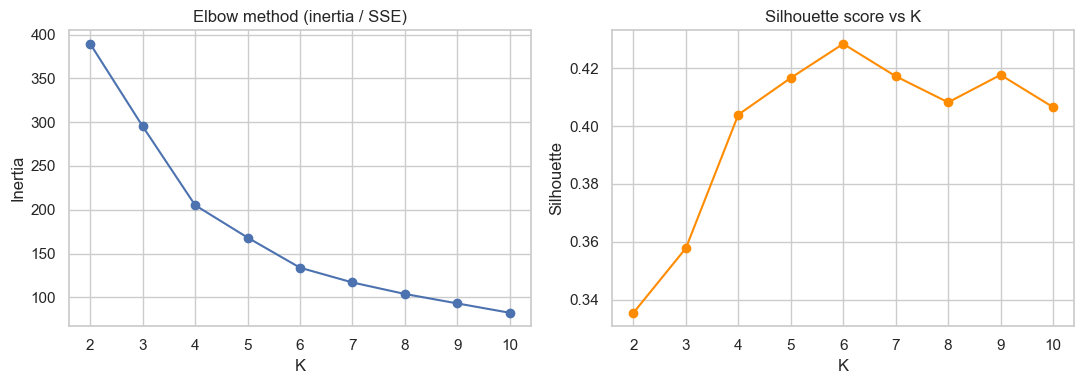

In [150]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(param_df['K'], param_df['inertia'], marker='o')
axes[0].set_title('Elbow method (inertia / SSE)')
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inertia')
axes[1].plot(param_df['K'], param_df['silhouette'], marker='o', color='darkorange')
axes[1].set_title('Silhouette score vs K')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.savefig('kmeans_parameter_selection.png', dpi=120, bbox_inches='tight')
plt.show()

In [151]:
best_k = int(param_df.sort_values('silhouette', ascending=False).iloc[0]['K'])
print('Selected K (highest silhouette on this grid):', best_k)

kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
customer_df_copy['kmeans_cluster'] = kmeans.fit_predict(X_scaled)
centers_original = scaler.inverse_transform(kmeans.cluster_centers_)
centers_df = pd.DataFrame(centers_original, columns=feature_cols)
centers_df.index.name = 'cluster'
display(centers_df.round(1))
print('Inertia:', round(kmeans.inertia_, 2))
print('Silhouette:', round(silhouette_score(X_scaled, customer_df_copy['kmeans_cluster']), 3))

Selected K (highest silhouette on this grid): 6


,Age,Annual Income (k$),Spending Score (1-100)
cluster,,,
0,56.3,54.3,49.1
1,26.8,57.1,48.1
2,41.9,88.9,17.0
3,32.7,86.5,82.1
4,25.0,25.3,77.6
5,45.5,26.3,19.4


Inertia: 133.87
Silhouette: 0.428


## 6. Evaluation & Visualization

**Required metrics** (compute for your final K-Means model, on the full scaled dataset):
- Inertia (SSE)
- Silhouette Score
- Davies-Bouldin Index

Present these in a small summary table.

**Required visualizations** (3 total):
1. **Elbow plot** -> inertia (y-axis) vs. k (x-axis), from Section 5.
2. **Silhouette score plot** -> silhouette score (y-axis) vs. k (x-axis), with your chosen k clearly marked.
3. **PCA cluster scatter plot** -> reduce `X_scaled` to 2 dimensions with PCA (`PC1`, `PC2`) and plot the customers colored by their final cluster label, so the clusters can be seen in 2D.


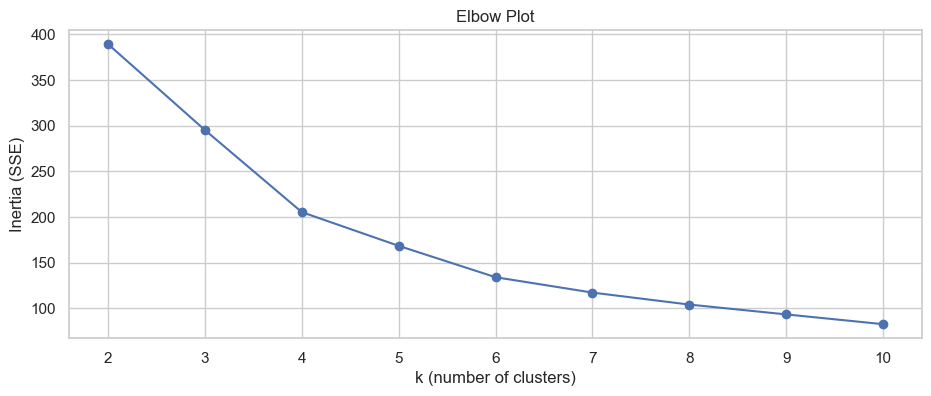

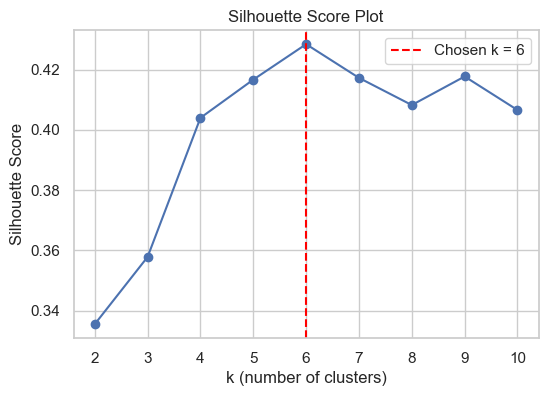

                 Metric       Value
0         Inertia (SSE)  134.352775
1      Silhouette Score    0.431065
2  Davies-Bouldin Index    0.834966


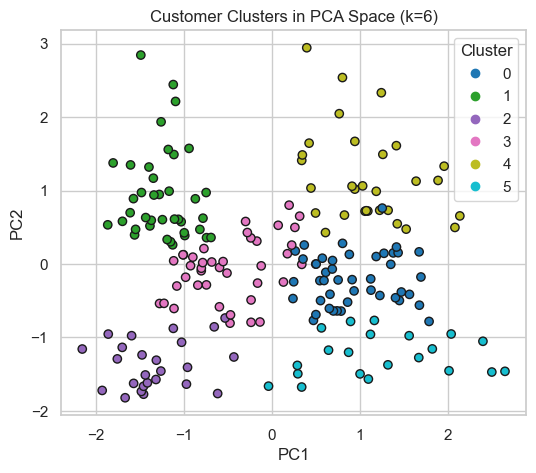

In [154]:
# Step 1: Loop over a range of k to collect metrics




# Visualization 1: Elbow plot (inertia vs k)
plt.figure(figsize=(11, 4))
plt.plot(list(k_values), inertias, marker='o')
plt.xlabel('k (number of clusters)')
plt.ylabel('Inertia (SSE)')
plt.title('Elbow Plot')
plt.show()

# Visualization 2: Silhouette score plot (score vs k)
chosen_k = best_k

plt.figure(figsize=(6, 4))
plt.plot(list(k_values), sil_scores, marker='o')
plt.axvline(x=chosen_k, color='red', linestyle='--', label=f'Chosen k = {chosen_k}')
plt.xlabel('k (number of clusters)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Plot')
plt.legend()
plt.show()

kmeans_final = KMeans(n_clusters=chosen_k, random_state=42)
final_labels = kmeans_final.fit_predict(X_scaled)

final_inertia = kmeans_final.inertia_
final_silhouette = silhouette_score(X_scaled, final_labels)
final_db = davies_bouldin_score(X_scaled, final_labels)

metrics_summary = pd.DataFrame({
    'Metric': ['Inertia (SSE)', 'Silhouette Score', 'Davies-Bouldin Index'],
    'Value': [final_inertia, final_silhouette, final_db]
})
print(metrics_summary)

# Visualization 3: PCA cluster scatter plot
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(6, 5))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=final_labels, cmap='tab10', edgecolor='k')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title(f'Customer Clusters in PCA Space (k={chosen_k})')
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.show()


In [155]:
customer_df['cluster'] = final_labels  # attach labels back to original (unscaled) dataframe
customer_df[customer_df['cluster'] == 4][['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Gender']].describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,30.000000,30.000000,30.000000
mean,44.000000,90.133333,17.933333
std,8.081482,16.919145,9.888807
min,32.000000,71.000000,1.000000
25%,37.000000,78.000000,11.500000
50%,43.500000,87.000000,16.500000
75%,47.750000,98.750000,23.750000
max,59.000000,137.000000,39.000000


## 7. Reflection Questions (write short answers, 1-2 sentences each)

1. Which value of k did you choose, and did the elbow plot and the silhouette plot agree? If not, how did you decide?

- The chosen k was 6, As the number of clusters increase, inertia reduces. IHowever, the silhoutte score disagrees, it has an upward-downward pattern, peaking at k=6

2. Look at the PCA scatter plot -> do the clusters look compact and well-separated, or do they overlap? What does that tell you about cluster quality?

- There is no doubt that there is some overlap in the middle region between cluster 0, 3 and 5. 1, 2 and 4 seem to be the most separated. Considering that we got a silhouette score of 0.43 which is around the middle of the scale, it shows that the clusters aren't fully separated.

3. Pick one cluster and describe the "typical customer" in it, using Age, Annual Income, and Spending Score (you may also look at the Gender breakdown for extra color, even though Gender wasn't used as a clustering feature).

- This cluster is made up of older, high-income, but low-spending customers. The typical customer is around 44 years old (ranging mostly 37–48), has a fairly high annual income averaging $90k (ranging $78k–$99k, up to $137k), but a notably low spending score averaging ~18 (out of 100) — with most customers scoring between 11 and 24.

4. If you had to explain K-Means to someone who has never studied ML, what is the one-sentence idea behind it?

- K-Means establishes a similarity between customers and groups them.

5. What are the main limitations of K-Means for this dataset (think about cluster shape, sensitivity to scaling, sensitivity to initial centroids)?
- K-Means assumes clusteers are roughly round and similarly sized, so irregularly-shaped groupings defeat it's purpose. It is also sensitive to feature scaling, that's why we applied a scaler in the beginning. 


## 8. Deliverables Checklist

Before the group debrief, make sure your notebook contains:

- [ ] Data loaded and cleaned (Section 2)
- [ ] Preprocessing/reproducibility setup completed (Section 3)
- [ ] Model trained with the required libraries (Section 4)
- [ ] Elbow and silhouette analysis completed, best k chosen (Section 5)
- [ ] All 3 required metrics reported (Section 6):
   - Inertia (SSE)
   - Silhouette Score
   - Davies-Bouldin Index
- [ ] All 3 required visualizations (Section 6):
   - Elbow plot
   - Silhouette score plot
   - PCA cluster scatter plot
- [ ] Reflection questions answered (Section 7)
---

## 9. Group Debrief (do this together, after everyone has finished)

Bring your metrics table and your 3 visualizations to the group. As a group, discuss:

- Whose model found the "cleanest" clusters (highest Silhouette, lowest Davies-Bouldin)?
- Did everyone converge on the same value of k? If not, why might that be?
- How do your K-Means clusters compare to your groupmate's DBSCAN clusters (Exercise 2) -> same number of groups? Same customers grouped together?
- If this segmentation were used by a marketing team, which cluster would you target first, and why?
